# 02. Modeling: Predicting Online Purchases

**Goal:** start from an OLS linear probability model (primary, interpretable model), then compare it with 4 classification models for predicting whether a session ends in a purchase (`Revenue`).

**Design choices**
- Data: `clean_df` = drop `Other` visitors + duplicates. **No outlier filter**: it removed 38% of buyers, and tree models handle extreme values.
- One stratified 80/20 train/test split, used by every model.
- Metrics: **AUC** (main), precision, recall, F1. Not accuracy: only ~15% of sessions buy.
- Every model is run **with and without `PageValues`**, because PageValues is computed from purchases (leakage risk).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.class_weight import compute_sample_weight
import statsmodels.api as sm
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, RocCurveDisplay
from xgboost import XGBClassifier

## 1. Load and clean

In [2]:
df = pd.read_csv('data/online_shoppers_intention.csv')

clean_df = df[df['VisitorType'] != 'Other'].drop_duplicates().copy()
clean_df['converted_revenue'] = clean_df['Revenue'].astype(int)

print(clean_df.shape)
print('Purchase rate:', round(clean_df['converted_revenue'].mean(), 3))

(12124, 19)
Purchase rate: 0.156


## 2. Features
- Numeric: page counts, durations, bounce/exit rates, SpecialDay, PageValues
- Categorical (one-hot): Month, VisitorType, OperatingSystems, Browser, Region, TrafficType
- Weekend as 0/1

In [3]:
numeric = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
           'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'PageValues']
categorical = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

X = pd.get_dummies(clean_df[numeric + categorical + ['Weekend']],
                   columns=categorical, drop_first=True, dtype=int)
X['Weekend'] = X['Weekend'].astype(int)
y = clean_df['converted_revenue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (9699, 67)  Test: (2425, 67)


## 3. Primary model: OLS (linear probability model)
OLS on the 0/1 outcome. Each coefficient = change in purchase probability per 1-unit change in X, holding the other variables constant.
Fit on the **training set** with HC1 robust standard errors, with and without PageValues.

In [4]:
X_train_c = sm.add_constant(X_train.astype(float))

ols_pv    = sm.OLS(y_train, X_train_c).fit(cov_type='HC1')
ols_no_pv = sm.OLS(y_train, X_train_c.drop(columns='PageValues')).fit(cov_type='HC1')

print('R-squared with PageValues:   ', round(ols_pv.rsquared, 3))
print('R-squared without PageValues:', round(ols_no_pv.rsquared, 3))
ols_no_pv.summary()

R-squared with PageValues:    0.285
R-squared without PageValues: 0.101


/var/folders/8v/v2c4n_w51456g3mxc_p0cd200000gn/T/ipykernel_47443/1323346799.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_pv    = sm.OLS(y_train, X_train_c).fit(cov_type='HC1')
/var/folders/8v/v2c4n_w51456g3mxc_p0cd200000gn/T/ipykernel_47443/1323346799.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_no_pv = sm.OLS(y_train, X_train_c.drop(columns='PageValues')).fit(cov_type='HC1')
/usr/local/Caskroom/miniconda/base/envs/ecommerce/lib/python3.12/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 66, but rank is 63
  res = self.wald_test(


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      converted_revenue   R-squared:                       0.101
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     32.45
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:57:59   Log-Likelihood:                -3417.3
No. Observations:                9699   AIC:                             6965.
Df Residuals:                    9634   BIC:                             7431.
Df Model:                          64                                         
Covariance Type:                  HC1                                         
=================================================================================================
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             0.2415      0.028      8.753      0.000       0.187       0.296
Administrative                    0.0033      0.002      1.924      0.054   -6.15e-05       0.007
Administrative_Duration        -9.84e-07   3.11e-05     -0.032      0.975   -6.19e-05    5.99e-05
Informational                     0.0008      0.004      0.172      0.863      -0.008       0.009
Informational_Duration         4.685e-06   3.61e-05      0.130      0.897   -6.61e-05    7.55e-05
ProductRelated                 3.923e-05      0.000      0.188      0.851      -0.000       0.000
ProductRelated_Duration         1.55e-05   5.09e-06      3.042      0.002    5.51e-06    2.55e-05
BounceRates                       1.1751      0.121      9.748      0.000       0.939       1.411
ExitRates                        -2.0141      0.149    -13.556      0.000      -2.305      -1.723
SpecialDay                       -0.0486      0.015     -3.303      0.001      -0.077      -0.020
Weekend                           0.0080      0.009      0.900      0.368      -0.009       0.025
Month_Dec                        -0.0698      0.022     -3.137      0.002      -0.113      -0.026
Month_Feb                        -0.0769      0.024     -3.150      0.002      -0.125      -0.029
Month_Jul                        -0.0110      0.028     -0.394      0.693      -0.066       0.044
Month_June                       -0.0591      0.028     -2.118      0.034      -0.114      -0.004
Month_Mar                        -0.0650      0.022     -2.975      0.003      -0.108      -0.022
Month_May                        -0.0449      0.021     -2.088      0.037      -0.087      -0.003
Month_Nov                         0.0548      0.022      2.480      0.013       0.011       0.098
Month_Oct                        -0.0037      0.028     -0.135      0.893      -0.058       0.051
Month_Sep                        -0.0130      0.029     -0.448      0.654      -0.070       0.044
VisitorType_Returning_Visitor    -0.0575      0.013     -4.260      0.000      -0.084      -0.031
OperatingSystems_2                0.0357      0.021      1.697      0.090      -0.006       0.077
OperatingSystems_3               -0.0137      0.021     -0.637      0.524      -0.056       0.028
OperatingSystems_4                0.0338      0.021      1.610      0.107      -0.007       0.075
OperatingSystems_5                0.0133      0.096      0.139      0.889      -0.174       0.201
OperatingSystems_6               -0.0173      0.090     -0.193      0.847      -0.193       0.158
OperatingSystems_7                0.0698      0.122      0.571      0.568      -0.170       0.309
OperatingSystems_8               -0.0635      0.064     -0.988      0.323      -0.189       0.062
Browser_2                        -0.0163     

In [5]:
# significant coefficients (p < 0.05) of the model without PageValues, largest first
coef = pd.DataFrame({'coef': ols_no_pv.params, 'p_value': ols_no_pv.pvalues}).drop('const')
coef[coef['p_value'] < 0.05].sort_values('coef', key=abs, ascending=False).round(4)

,coef,p_value
ExitRates,-2.0141,0.0000
BounceRates,1.1751,0.0000
TrafficType_16,-0.1774,0.0000
TrafficType_8,0.0995,0.0004
TrafficType_20,0.0906,0.0238
Month_Feb,-0.0769,0.0016
TrafficType_18,-0.0716,0.0171
Month_Dec,-0.0698,0.0017
Month_Mar,-0.0650,0.0029
TrafficType_15,-0.0649,0.0004


To compare OLS with the ML models on the same test set, the wrapper below makes OLS behave like a classifier:
predictions are clipped to 0–1 and used as purchase probabilities. Balanced sample weights match the class weighting of the other models.

In [6]:
class OLSClassifier(ClassifierMixin, BaseEstimator):
    """OLS linear probability model with a predict_proba method."""
    def fit(self, X, y):
        self.model_ = LinearRegression().fit(X, y, sample_weight=compute_sample_weight('balanced', y))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = np.clip(self.model_.predict(X), 0, 1)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

## 4. ML models
`class_weight='balanced'` / `scale_pos_weight` make the models pay more attention to the rare buyers.

In [7]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

def make_models():
    return {
        'OLS (linear probability)': OLSClassifier(),
        'Logistic regression': make_pipeline(StandardScaler(),
                                             LogisticRegression(class_weight='balanced', max_iter=2000)),
        'Decision tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
        'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                class_weight='balanced', random_state=42, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                 scale_pos_weight=pos_weight, eval_metric='auc', random_state=42),
    }

## 5. Train and evaluate (with and without PageValues)

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results, fitted = [], {}

for feature_set in ['With PageValues', 'Without PageValues']:
    cols = X.columns if feature_set == 'With PageValues' else X.columns.drop('PageValues')

    for name, model in make_models().items():
        cv_auc = cross_val_score(model, X_train[cols], y_train, cv=cv, scoring='roc_auc').mean()
        model.fit(X_train[cols], y_train)

        prob = model.predict_proba(X_test[cols])[:, 1]
        pred = (prob >= 0.5).astype(int)

        results.append({'Features': feature_set, 'Model': name,
                        'CV AUC (train)': cv_auc,
                        'Test AUC': roc_auc_score(y_test, prob),
                        'Precision': precision_score(y_test, pred),
                        'Recall': recall_score(y_test, pred),
                        'F1': f1_score(y_test, pred)})
        fitted[(feature_set, name)] = (model, cols)

results_df = pd.DataFrame(results).round(3)
results_df

,Features,Model,CV AUC (train),Test AUC,Precision,Recall,F1
0,With PageValues,OLS (linear probability),0.855,0.859,0.390,0.780,0.520
1,With PageValues,Logistic regression,0.898,0.901,0.479,0.788,0.596
2,With PageValues,Decision tree,0.914,0.916,0.477,0.876,0.618
3,With PageValues,Random forest,0.929,0.927,0.542,0.860,0.665
4,With PageValues,XGBoost,0.930,0.928,0.531,0.862,0.657
5,Without PageValues,OLS (linear probability),0.745,0.742,0.264,0.759,0.392
6,Without PageValues,Logistic regression,0.747,0.740,0.264,0.746,0.390
7,Without PageValues,Decision tree,0.748,0.719,0.276,0.635,0.385
8,Without PageValues,Random forest,0.779,0.775,0.311,0.659,0.422
9,Without PageValues,XGBoost,0.777,0.767,0.280,0.704,0.401


## 6. Comparison: test AUC

In [9]:
results_df.pivot(index='Model', columns='Features', values='Test AUC') \
          .sort_values('Without PageValues', ascending=False)

Features,With PageValues,Without PageValues
Model,,
Random forest,0.927,0.775
XGBoost,0.928,0.767
OLS (linear probability),0.859,0.742
Logistic regression,0.901,0.740
Decision tree,0.916,0.719


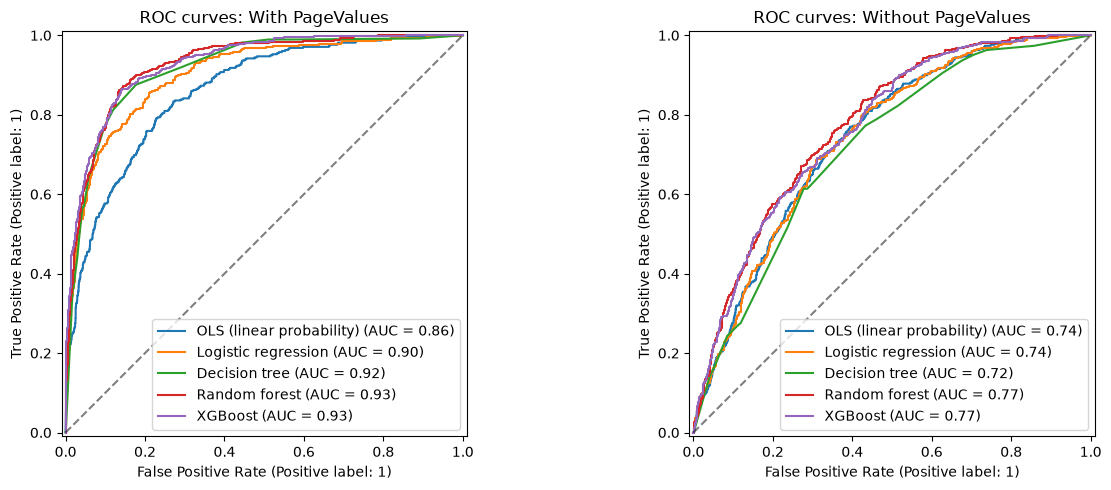

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, feature_set in zip(axes, ['With PageValues', 'Without PageValues']):
    for name in make_models():
        model, cols = fitted[(feature_set, name)]
        RocCurveDisplay.from_estimator(model, X_test[cols], y_test, name=name, ax=ax)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    ax.set_title(f'ROC curves: {feature_set}')

plt.tight_layout()
plt.show()

## 7. Visualizing each model
- 7.1 Confusion matrices: what each model gets right and wrong on the test set
- 7.2 Permutation importance: the **same** importance measure for all 5 models (how much test AUC drops when a feature is shuffled), so models can be compared directly
- 7.3 Model-specific views: OLS and logistic coefficients, the decision tree's rules, random forest and XGBoost built-in importance

### 7.1 Confusion matrices

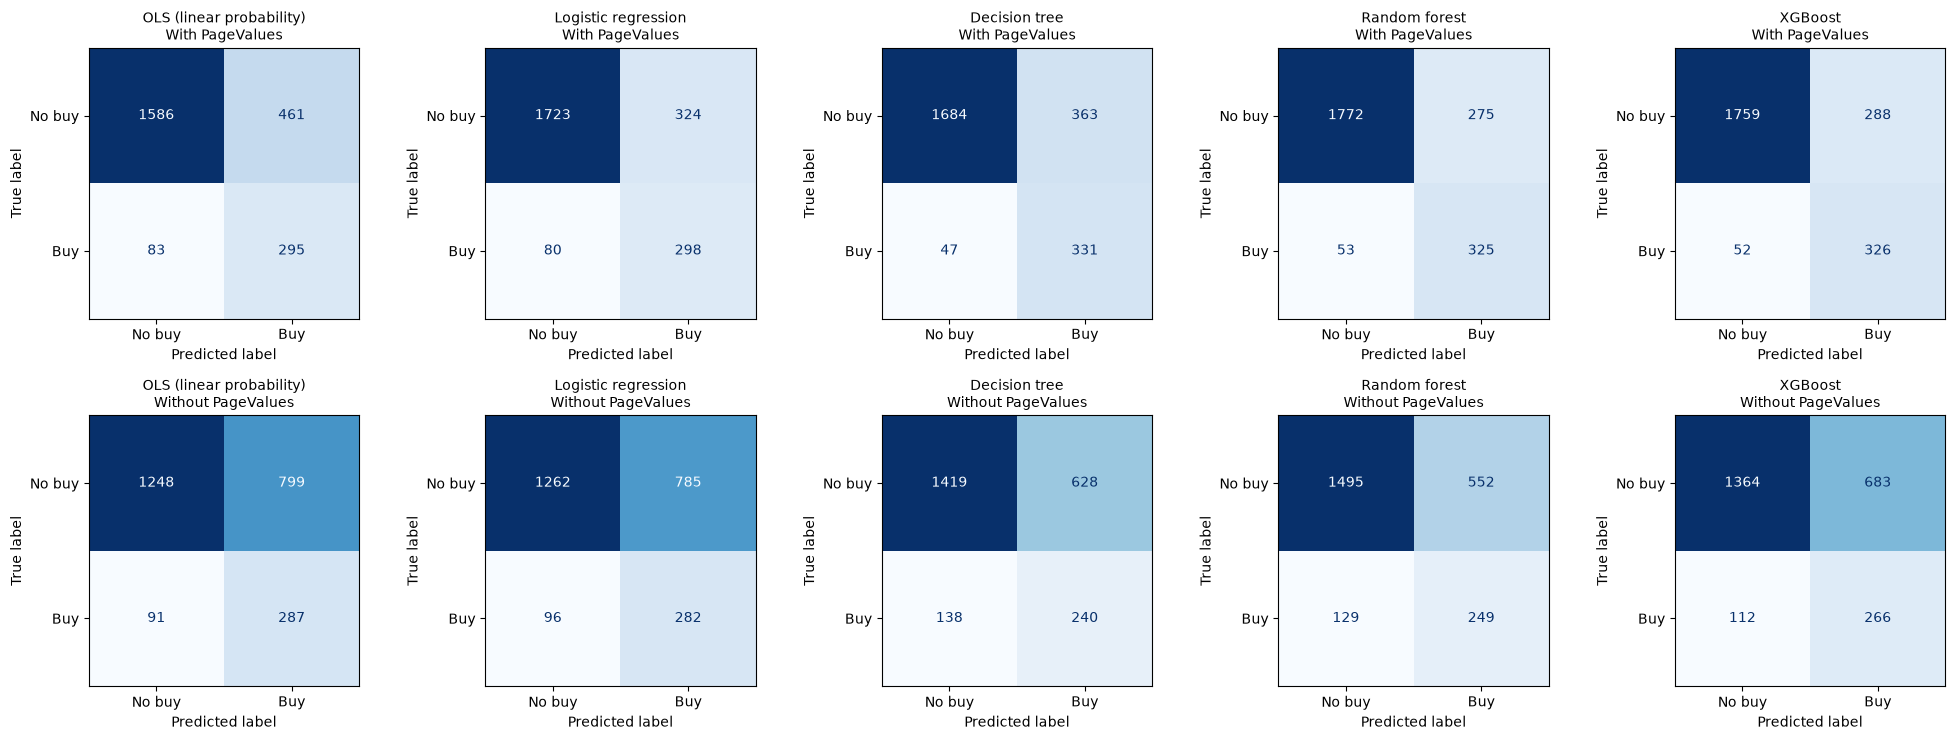

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

names = list(make_models())
fig, axes = plt.subplots(2, len(names), figsize=(4 * len(names), 7.5))

for r, feature_set in enumerate(['With PageValues', 'Without PageValues']):
    for c, name in enumerate(names):
        model, cols = fitted[(feature_set, name)]
        ConfusionMatrixDisplay.from_estimator(model, X_test[cols], y_test, ax=axes[r, c],
                                              display_labels=['No buy', 'Buy'], colorbar=False, cmap='Blues')
        axes[r, c].set_title(f'{name}\n{feature_set}', fontsize=10)

plt.tight_layout()
plt.show()

### 7.2 Permutation importance (all models, same measure)

/usr/local/Caskroom/miniconda/base/envs/ecommerce/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/usr/local/Caskroom/miniconda/base/envs/ecommerce/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


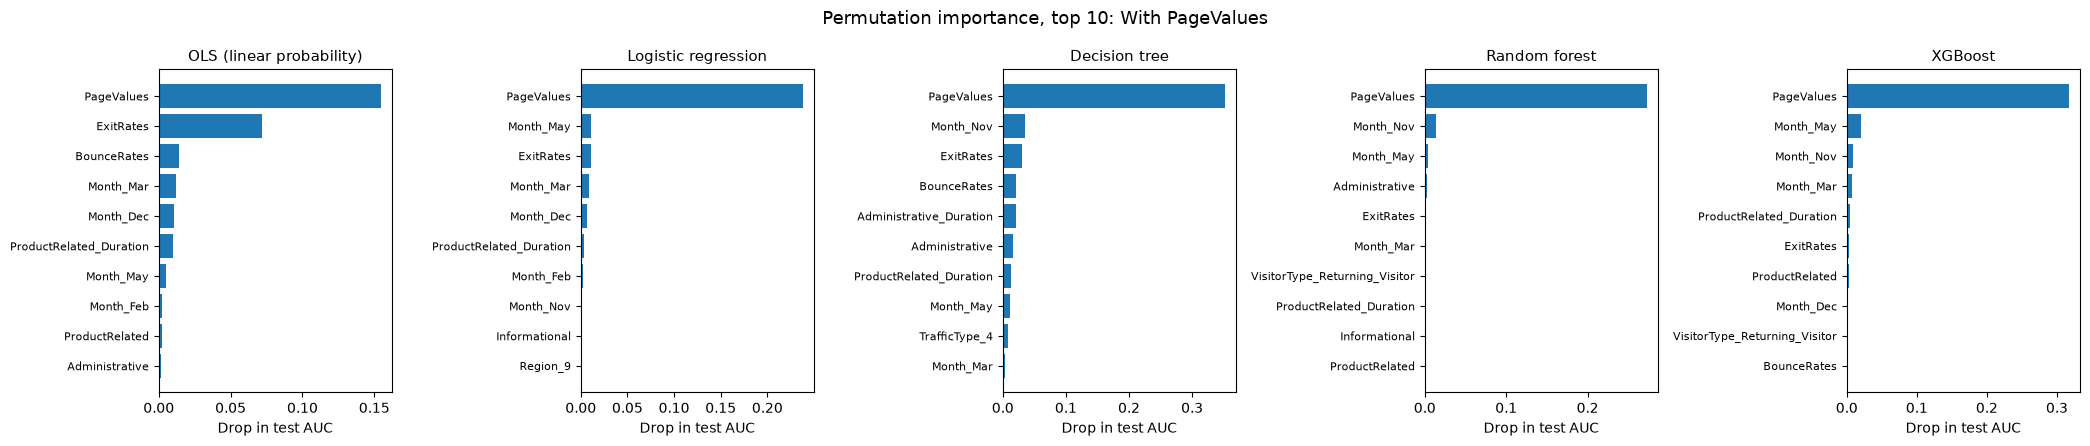

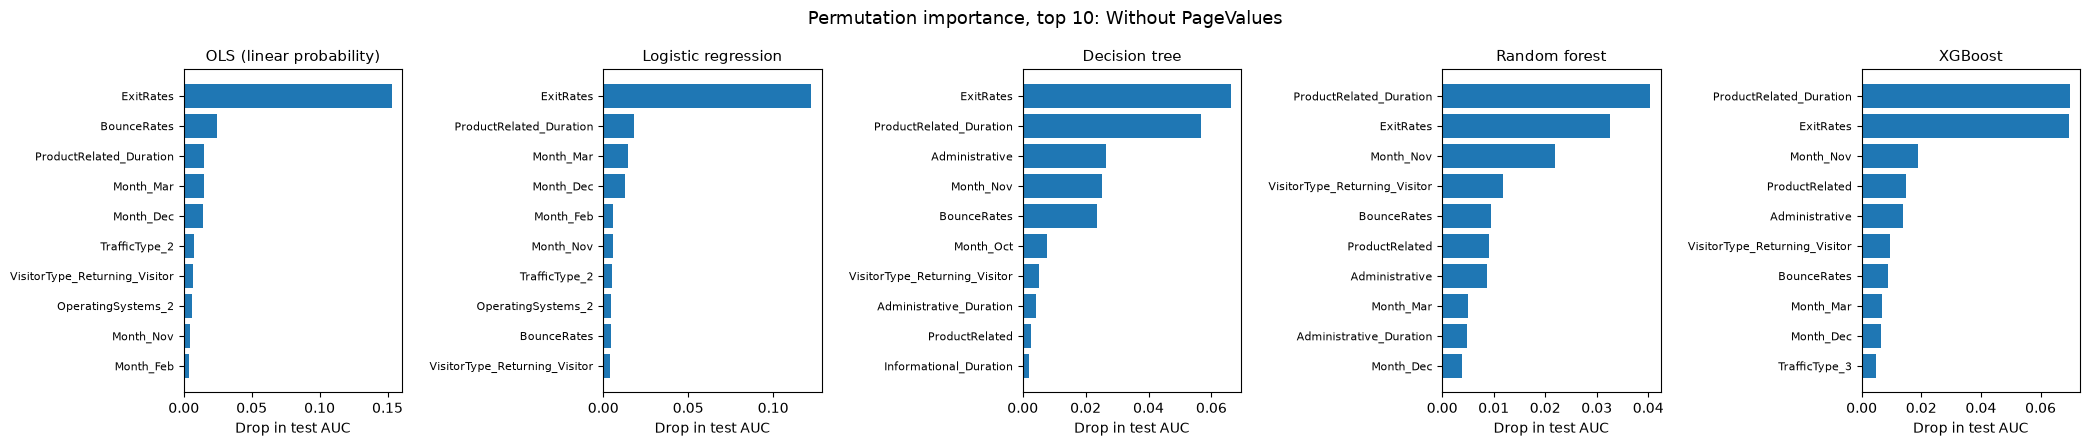

In [12]:
from sklearn.inspection import permutation_importance

perm = {}
for key, (model, cols) in fitted.items():
    r = permutation_importance(model, X_test[cols], y_test, scoring='roc_auc',
                               n_repeats=5, random_state=42, n_jobs=-1)
    perm[key] = pd.Series(r.importances_mean, index=cols)

for feature_set in ['With PageValues', 'Without PageValues']:
    fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4.5))
    for ax, name in zip(axes, names):
        top = perm[(feature_set, name)].sort_values().tail(10)
        ax.barh(top.index, top.values)
        ax.set_title(name, fontsize=11)
        ax.set_xlabel('Drop in test AUC')
        ax.tick_params(axis='y', labelsize=8)
    fig.suptitle(f'Permutation importance, top 10: {feature_set}', fontsize=13)
    plt.tight_layout()
    plt.show()

### 7.3 Model-specific views (without PageValues)
**OLS (primary model):** significant coefficients with 95% CI, = change in purchase probability per 1-unit change.

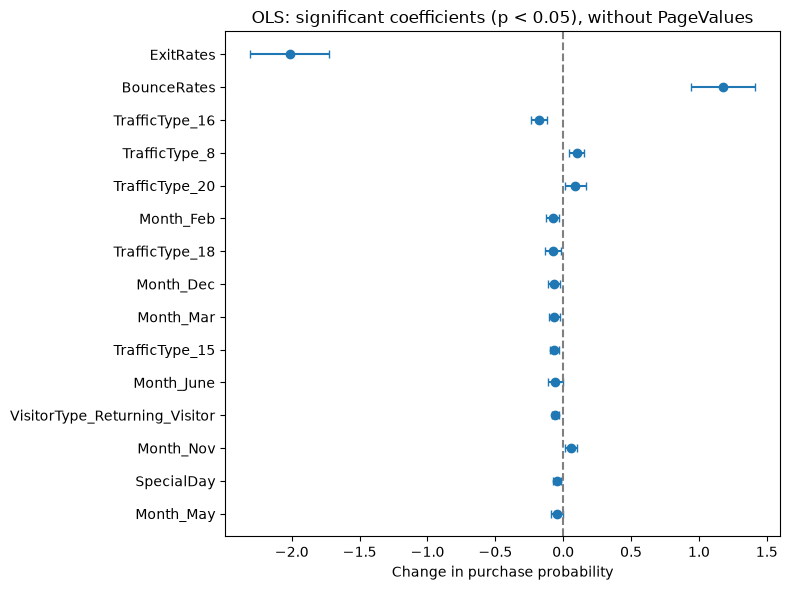

In [13]:
ci = ols_no_pv.conf_int().drop('const')
coef = ols_no_pv.params.drop('const')
sig = ols_no_pv.pvalues.drop('const') < 0.05
top = coef[sig].sort_values(key=abs).tail(15)

plt.figure(figsize=(8, 6))
plt.errorbar(top, top.index, xerr=[top - ci.loc[top.index, 0], ci.loc[top.index, 1] - top], fmt='o', capsize=3)
plt.axvline(0, color='grey', linestyle='--')
plt.xlabel('Change in purchase probability')
plt.title('OLS: significant coefficients (p < 0.05), without PageValues')
plt.tight_layout()
plt.show()

**Logistic regression:** coefficients on standardized features, so their sizes are comparable. Blue = raises purchase odds, red = lowers them.

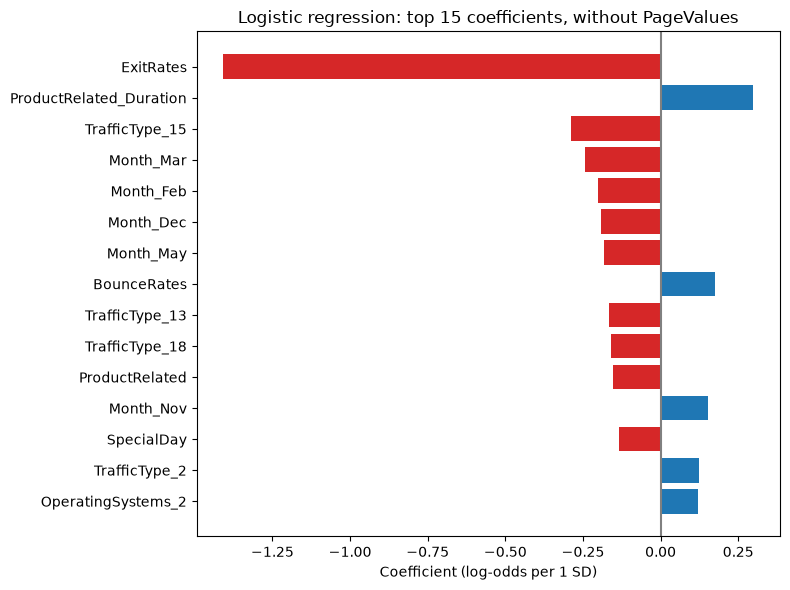

In [14]:
model, cols = fitted[('Without PageValues', 'Logistic regression')]
lr_coef = pd.Series(model.named_steps['logisticregression'].coef_[0], index=cols)
top = lr_coef.sort_values(key=abs).tail(15)

plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=['tab:blue' if v > 0 else 'tab:red' for v in top])
plt.axvline(0, color='grey')
plt.xlabel('Coefficient (log-odds per 1 SD)')
plt.title('Logistic regression: top 15 coefficients, without PageValues')
plt.tight_layout()
plt.show()

**Decision tree:** the first 3 levels of the tree, i.e. the rules it uses to split buyers from non-buyers.

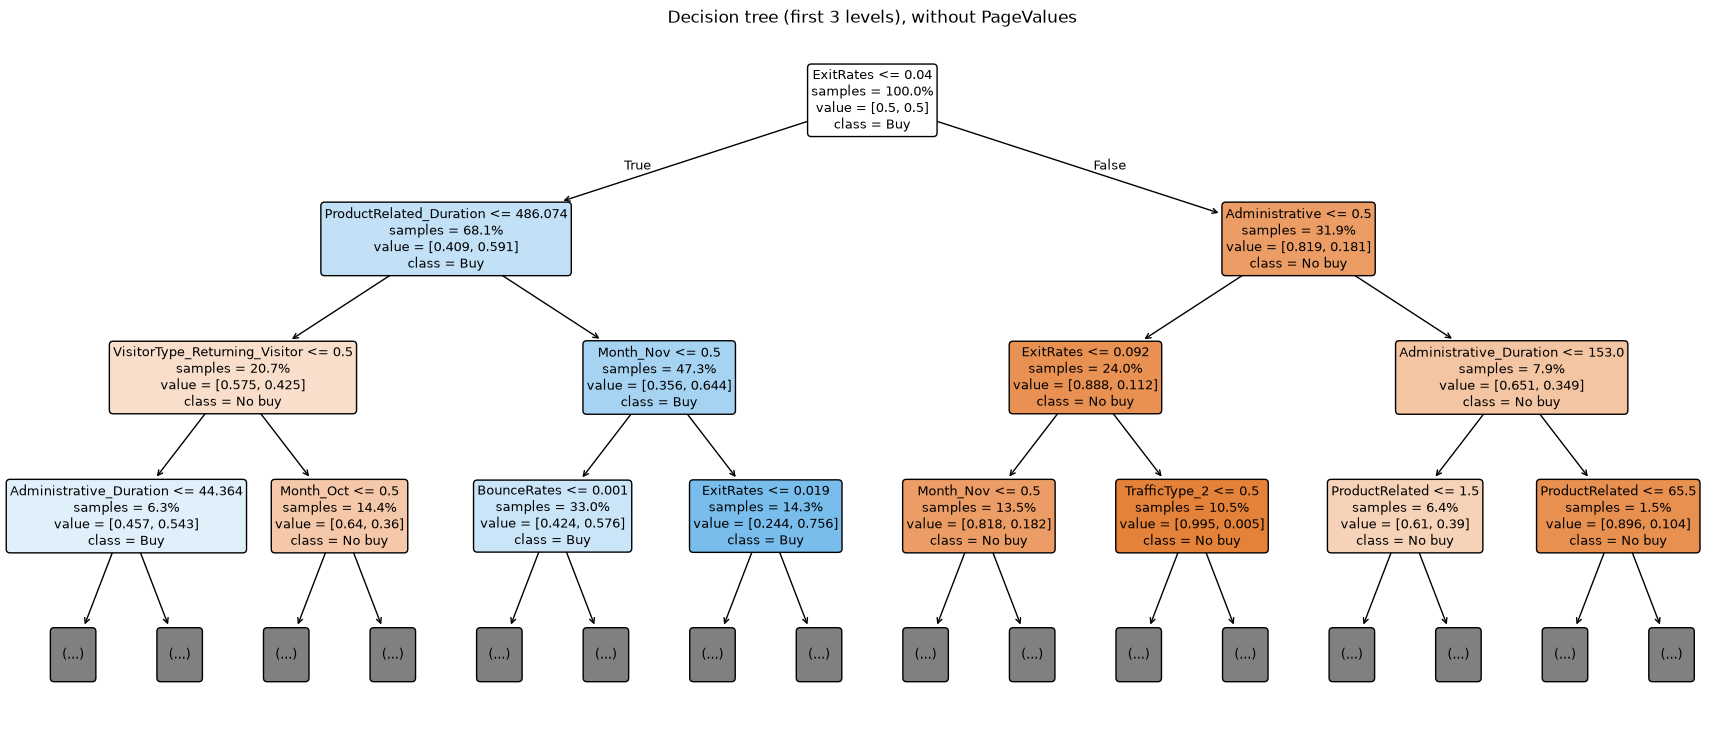

In [15]:
from sklearn.tree import plot_tree

model, cols = fitted[('Without PageValues', 'Decision tree')]
plt.figure(figsize=(22, 9))
plot_tree(model, feature_names=list(cols), class_names=['No buy', 'Buy'],
          max_depth=3, filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title('Decision tree (first 3 levels), without PageValues')
plt.show()

**Tree-based models:** built-in feature importance (share of total split improvement).

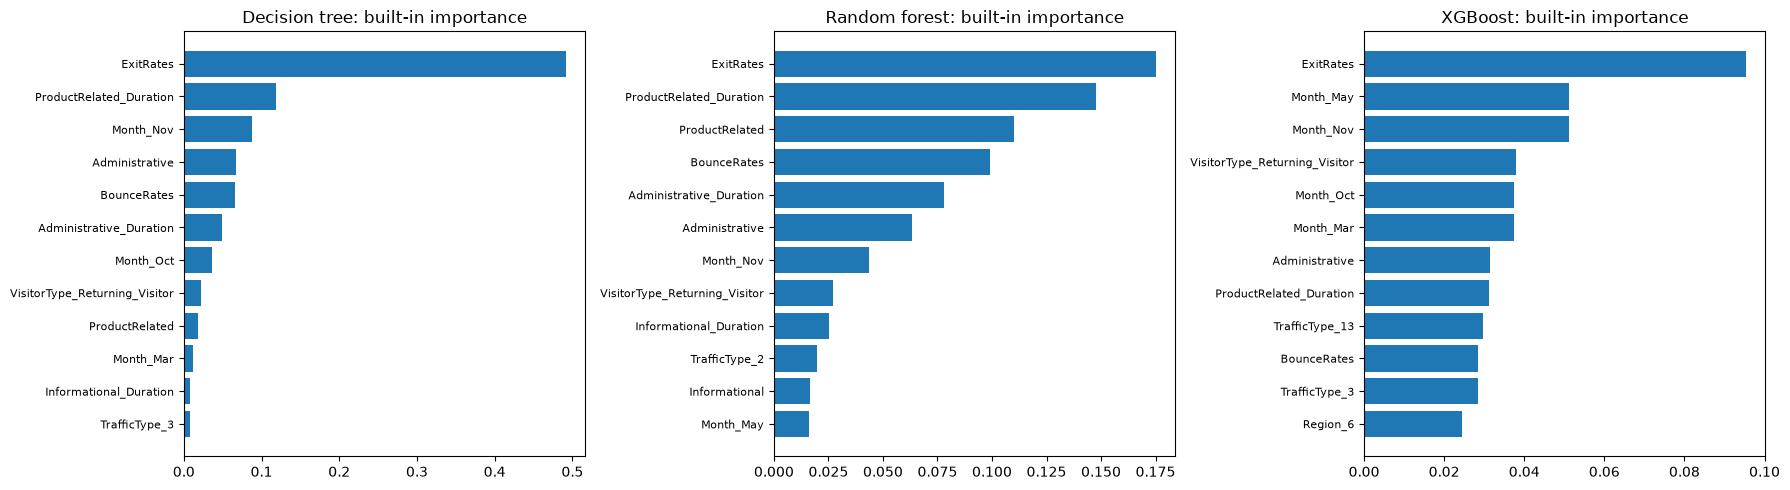

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, ['Decision tree', 'Random forest', 'XGBoost']):
    model, cols = fitted[('Without PageValues', name)]
    imp = pd.Series(model.feature_importances_, index=cols).sort_values().tail(12)
    ax.barh(imp.index, imp.values)
    ax.set_title(f'{name}: built-in importance')
    ax.tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.show()

## 8. Findings (write after running)
- How the primary OLS model compares with the ML models (AUC, precision, recall):
- Best model and its AUC with / without PageValues:
- How much performance drops without PageValues, and what that says about leakage:
- Top features without PageValues, and how they compare with the regression results in 01_eda:
- Precision vs. recall trade-off: what would a business do with this model?